# Módulo 18: KDD y CRISP-DM — Solución

> Solución de referencia de la guía [m18-kdd-crisp-dm-guia.ipynb](m18-kdd-crisp-dm-guia.ipynb). No es una tarea entregada del programa.

Lección: [m18-kdd-crisp-dm-leccion.md](m18-kdd-crisp-dm-leccion.md)

## Contexto

**CineNube** es un servicio ficticio de películas y series por suscripción. En el último año, cada vez más suscriptores cancelan, y la dirección quiere reducir el abandono antes de invertir más en captar clientes nuevos, que cuesta varias veces más que retener a uno.

El equipo de retención puede llamar cada mes al **10 % de los suscriptores activos** para ofrecerles un descuento o un cambio de plan. Hoy elige a quién llamar casi al azar. Se pide un modelo que ordene a los suscriptores por riesgo de abandono, para que esas llamadas lleguen a quienes de verdad están a punto de irse, y que el proyecto se organice con una metodología reconocida.

## Datos

La celda inicial genera, con una semilla fija, dos DataFrames:

- `clientes`: 4000 suscriptores de un periodo pasado, con la columna `abandono` que indica si cancelaron en los tres meses siguientes. Sirve para entrenar y evaluar el modelo.
- `cartera`: 1000 suscriptores activos hoy, con las mismas columnas salvo `abandono`, porque todavía no se sabe quién se irá. Es la cartera que hay que puntuar.

| Columna | Descripción |
| --- | --- |
| `cliente_id` | Identificador del suscriptor |
| `tipo_contrato` | `mensual` (se puede cancelar cualquier mes) o `anual` |
| `metodo_pago` | `tarjeta`, `domiciliado` (cargo automático a la cuenta bancaria) o `manual` (el cliente paga cada mes) |
| `antiguedad_meses` | Meses como suscriptor |
| `cargo_mensual` | Importe mensual en dólares, incluidos los complementos contratados |
| `horas_uso_semana` | Horas de visualización por semana en el último mes. Tiene valores faltantes: la aplicación no registró el uso de algunos clientes |
| `llamadas_soporte` | Contactos con soporte técnico en los últimos tres meses |
| `abandono` | 1 si canceló en los tres meses siguientes, 0 si no (solo en `clientes`) |

## Instrucciones

1. **Las seis fases de CRISP-DM en CineNube.** Concretar preguntas, actividades y entregable de cada fase.
2. **KDD frente a CRISP-DM.** Relacionar las etapas de KDD con las fases de CRISP-DM y explicar las diferencias.
3. **¿Qué metodología conviene?** Recomendar una, justificarla y mitigar su principal desventaja.
4. **Comprensión de los datos.** Estructura, faltantes, tasa de abandono global y por grupos, y figura.
5. **Preparación de los datos.** Dummies y división estratificada en entrenamiento y prueba.
6. **Modelado y evaluación.** `Pipeline` con imputación, escalado y regresión logística; matriz de confusión, recall, precisión, ROC AUC y coeficientes.
7. **Despliegue: a quién llamar este mes.** Captura del 10 % de mayor riesgo, curva de captura y lista de la cartera.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)


def generar(n):
    """Suscriptores sintéticos; el abandono sigue un modelo logístico de sus variables."""
    contrato = rng.choice(["mensual", "anual"], size=n, p=[0.6, 0.4])
    antiguedad = np.where(contrato == "anual", rng.integers(6, 61, n), rng.integers(1, 49, n))
    pago = rng.choice(["tarjeta", "domiciliado", "manual"], size=n, p=[0.45, 0.35, 0.20])
    cargo = rng.choice([6.99, 10.99, 15.99], size=n, p=[0.35, 0.45, 0.20]) + 2.5 * rng.poisson(0.4, n)
    uso = np.round(rng.gamma(2.5, 2.4, n), 1)
    llamadas = rng.poisson(0.5 + 0.7 * (uso < 3), n)
    z = (-0.9 + 1.4 * (contrato == "mensual") + 0.6 * (pago == "manual") - 0.2 * (pago == "domiciliado")
         - 0.045 * antiguedad + 0.10 * (cargo - 10) + 0.5 * llamadas - 0.2 * uso)
    abandono = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
    uso_registrado = np.where(rng.random(n) < 0.03, np.nan, uso)   # ~3 % sin registro
    return pd.DataFrame({
        "cliente_id": np.arange(1, n + 1),
        "tipo_contrato": contrato,
        "metodo_pago": pago,
        "antiguedad_meses": antiguedad,
        "cargo_mensual": cargo.round(2),
        "horas_uso_semana": uso_registrado,
        "llamadas_soporte": llamadas,
        "abandono": abandono,
    })


clientes = generar(4000)
cartera = generar(1000).drop(columns="abandono")
cartera["cliente_id"] += 10000

print("clientes:", clientes.shape, " cartera:", cartera.shape)
clientes.head()

clientes: (4000, 8)  cartera: (1000, 7)


,cliente_id,tipo_contrato,metodo_pago,antiguedad_meses,cargo_mensual,horas_uso_semana,llamadas_soporte,abandono
0,1,anual,domiciliado,41,10.99,3.3,0,0
1,2,mensual,manual,22,10.99,7.2,1,1
2,3,anual,tarjeta,20,6.99,NaN,0,0
3,4,anual,tarjeta,25,15.99,8.2,0,0
4,5,mensual,domiciliado,29,6.99,1.8,2,1


Cada fila de `clientes` es un suscriptor del periodo pasado con su resultado conocido; `cartera` tiene la misma estructura sin la columna `abandono`. El abandono se generó con un modelo logístico de las variables, así que hay una señal real que descubrir, mezclada con azar: dos clientes con el mismo perfil pueden tener destinos distintos.

### Tarea 1. Las seis fases de CRISP-DM en CineNube

**1. Comprensión del negocio**

- *Preguntas:* ¿cuánto cuesta un suscriptor que se va? ¿Qué capacidad tiene el equipo de retención? ¿Qué acciones puede ofrecer (descuento, cambio de plan, paso a contrato anual)?
- *Objetivo de negocio medible:* reducir la tasa de abandono trimestral en dos puntos porcentuales en un año.
- *Objetivo de minería de datos:* ordenar a los suscriptores activos por probabilidad de cancelar en los próximos tres meses.
- *Criterio de éxito:* que el 10 % de clientes que se llama cada mes concentre al menos el triple de abandonos que un 10 % elegido al azar, y que en un piloto la tasa de abandono del grupo llamado baje frente a un grupo de control.
- *Entregable:* plan del proyecto con objetivos, criterios de éxito, recursos y riesgos.

**2. Comprensión de los datos**

- *Preguntas:* ¿qué datos hay de contrato, pago, uso y soporte? ¿Cuál es la tasa de abandono? ¿Qué perfiles abandonan más? ¿Qué calidad tienen los datos?
- *Actividades:* reunir las tablas de suscripciones, facturación, registros de uso de la aplicación y tickets de soporte; explorar distribuciones y tasas por grupo; detectar faltantes (aquí, las horas de uso sin registrar).
- *Entregable:* informe de exploración y de calidad de datos (Tarea 4).

**3. Preparación de los datos**

- *Actividades:* definir la variable objetivo (cancelación en los tres meses siguientes a la fecha de corte), unir las fuentes por cliente, codificar las categorías como dummies, decidir cómo tratar los faltantes y separar entrenamiento y prueba.
- *Entregable:* conjunto de datos listo para modelar y su descripción (Tarea 5).

**4. Modelado**

- *Actividades:* elegir la técnica (regresión logística como punto de partida interpretable; después se podrían comparar árboles o ensambles), entrenarla y medir su calidad técnica (ROC AUC, recall) en datos que no vio.
- *Entregable:* modelo entrenado con sus parámetros y métricas (Tarea 6).

**5. Evaluación**

- *Preguntas:* ¿el modelo cumple el criterio de éxito **del negocio**, no solo una métrica? ¿Tiene sentido lo que aprende (por ejemplo, que más llamadas a soporte aumenten el riesgo)? ¿Se puede desplegar?
- *Actividades:* medir la captura con el presupuesto del 10 %, revisar el proceso completo por si se coló información del futuro y decidir si se despliega o se vuelve a una fase anterior.
- *Entregable:* evaluación de resultados y decisión de despliegue (Tarea 7, punto 1).

Conviene distinguir esta fase de la evaluación técnica dentro del modelado, que la lección agrupa en la fase 4: allí se comparan modelos entre sí; aquí se compara el modelo con el objetivo de CineNube.

**6. Despliegue**

- *Actividades:* puntuar cada mes la cartera activa, entregar la lista al equipo de retención, registrar qué se ofreció a cada cliente y qué pasó, monitorear el desempeño y reentrenar cuando se degrade.
- *Entregable:* plan de despliegue y de monitoreo, informe final y la lista mensual de clientes a contactar (Tarea 7, punto 3).

El ciclo es iterativo: si en la evaluación el modelo no captura suficientes abandonos, se vuelve a la preparación (por ejemplo, a crear variables nuevas) o incluso a la comprensión del negocio.

### Tarea 2. KDD frente a CRISP-DM

**Etapas de KDD y su correspondencia con CRISP-DM.** El proceso KDD (*Knowledge Discovery in Databases*), descrito por Fayyad, Piatetsky-Shapiro y Smyth en 1996, se resume en cinco etapas:

| Etapa de KDD | En CineNube | Fase de CRISP-DM |
| --- | --- | --- |
| Selección | Elegir los suscriptores y las variables relevantes (contrato, pago, uso, soporte) | Comprensión de los datos |
| Preprocesamiento | Limpiar datos, tratar las horas de uso sin registrar | Comprensión y preparación de los datos |
| Transformación | Crear dummies, escalar, construir variables nuevas | Preparación de los datos |
| Minería de datos | Ajustar la regresión logística | Modelado |
| Interpretación y evaluación | Leer coeficientes y métricas; convertir patrones en conocimiento | Modelado (evaluación técnica) y Evaluación |

**Diferencias**

- **El negocio al principio.** CRISP-DM empieza con una fase completa de comprensión del negocio, con objetivos y criterios de éxito. KDD presupone que se conoce el dominio y empieza por seleccionar los datos.
- **El despliegue al final.** CRISP-DM termina con el despliegue: poner el modelo en operación, monitorearlo y mantenerlo. En KDD el resultado es el **conocimiento** descubierto; cómo se usa en la operación queda fuera del proceso.
- **Qué pone en el centro.** KDD pone en el centro el descubrimiento de patrones en los datos: dedica tres de sus cinco etapas a prepararlos y la cuarta a extraer los patrones. Por eso la lección le atribuye más énfasis en la exploración.
- **Nivel de detalle.** CRISP-DM nació como estándar industrial (1999–2000) y detalla tareas y entregables para cada fase, lo que facilita gestionar y replicar proyectos. KDD es un marco conceptual más general.

Las dos son **iterativas**: en ambas se puede volver a etapas anteriores cuando los resultados no convencen.

### Tarea 3. ¿Qué metodología conviene?

**Recomendación: CRISP-DM.**

1. **El problema es de negocio, no de descubrimiento.** CineNube no busca "qué patrones hay en sus datos", sino reducir el abandono con un presupuesto de llamadas fijo. CRISP-DM obliga a fijar ese objetivo y el criterio de éxito antes de modelar, y la evaluación compara el modelo con ese criterio, como señala la lección.
2. **El valor está en el despliegue.** Un modelo que no se convierte en una lista mensual para el equipo de retención no reduce el abandono. CRISP-DM incluye el despliegue y el monitoreo; KDD termina en el conocimiento.
3. **Varios equipos implicados.** Marketing, retención, tecnología y finanzas necesitan saber qué se entrega y cuándo. La estructura de fases con entregables facilita gestionar el proyecto y comunicarlo.
4. **Proyecto recurrente.** El modelo se reentrenará y el método se podrá replicar para otros problemas (por ejemplo, la venta cruzada de planes), algo que la lección cita como ventaja de CRISP-DM.

**Desventaja y mitigación.** La lección advierte que CRISP-DM puede ser **rígido** y poner **menos énfasis en la exploración** que KDD. En CineNube eso podría llevar a modelar con las variables obvias y no descubrir, por ejemplo, que la caída del uso es la señal más fuerte. Se mitiga reservando tiempo explícito para la exploración en la comprensión de los datos, trabajando en iteraciones cortas (un primer modelo sencillo en pocas semanas, como el de este notebook) y aceptando volver atrás cuando la evaluación lo pida: el ciclo de CRISP-DM lo permite.

### Tarea 4. Comprensión de los datos

Primero revisamos la estructura: tipos de datos y valores faltantes.

In [2]:
clientes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cliente_id        4000 non-null   int64  
 1   tipo_contrato     4000 non-null   object 
 2   metodo_pago       4000 non-null   object 
 3   antiguedad_meses  4000 non-null   int64  
 4   cargo_mensual     4000 non-null   float64
 5   horas_uso_semana  3875 non-null   float64
 6   llamadas_soporte  4000 non-null   int64  
 7   abandono          4000 non-null   int64  
dtypes: float64(2), int64(4), object(2)
memory usage: 250.1+ KB


In [3]:
print("Valores faltantes por columna:")
print(clientes.isna().sum())

tasa_global = clientes["abandono"].mean() * 100
print(f"\nTasa de abandono global: {tasa_global:.1f} %")

Valores faltantes por columna:
cliente_id            0
tipo_contrato         0
metodo_pago           0
antiguedad_meses      0
cargo_mensual         0
horas_uso_semana    125
llamadas_soporte      0
abandono              0
dtype: int64

Tasa de abandono global: 19.6 %


Hay 4000 suscriptores y 8 columnas, con tipos correctos: dos categóricas (`object`) y el resto numéricas. La única columna con faltantes es `horas_uso_semana`, con 125 valores (3.1 %), que habrá que imputar en la preparación.

La tasa de abandono global es **19.6 %**: uno de cada cinco suscriptores cancela en tres meses. Las clases están desbalanceadas: un modelo que dijera siempre "se queda" acertaría el 80.4 % de las veces sin detectar a nadie. Por eso no evaluaremos con la exactitud (*accuracy*), sino con recall, precisión y ROC AUC.

Para comparar grupos usamos una función que calcula, por categoría, el número de clientes y la tasa de abandono en porcentaje. Las llamadas a soporte con 4 o más se agrupan en `4+`, porque hay muy pocos clientes en cada uno de esos valores.

In [4]:
def tasa_por(serie):
    """Número de clientes y tasa de abandono (%) por cada valor de `serie`."""
    return (clientes.groupby(serie)["abandono"]
            .agg(clientes="size", tasa_pct="mean")
            .assign(tasa_pct=lambda t: (t["tasa_pct"] * 100).round(1)))


llamadas_grupo = (clientes["llamadas_soporte"].clip(upper=4).astype(str)
                  .replace({"4": "4+"}).rename("llamadas_soporte"))

print(tasa_por(clientes["tipo_contrato"]), "\n")
print(tasa_por(clientes["metodo_pago"]), "\n")
print(tasa_por(llamadas_grupo))

               clientes  tasa_pct
tipo_contrato                    
anual              1579       7.4
mensual            2421      27.5 

             clientes  tasa_pct
metodo_pago                    
domiciliado      1441      16.6
manual            777      28.2
tarjeta          1782      18.2 

                  clientes  tasa_pct
llamadas_soporte                    
0                     2163      13.2
1                     1272      22.0
2                      417      36.5
3                      115      40.0
4+                      33      60.6


In [5]:
clientes.groupby("abandono")[["antiguedad_meses", "cargo_mensual", "horas_uso_semana"]].mean().round(2)

,antiguedad_meses,cargo_mensual,horas_uso_semana
abandono,,,
0,29.62,11.42,6.42
1,20.18,12.47,4.21


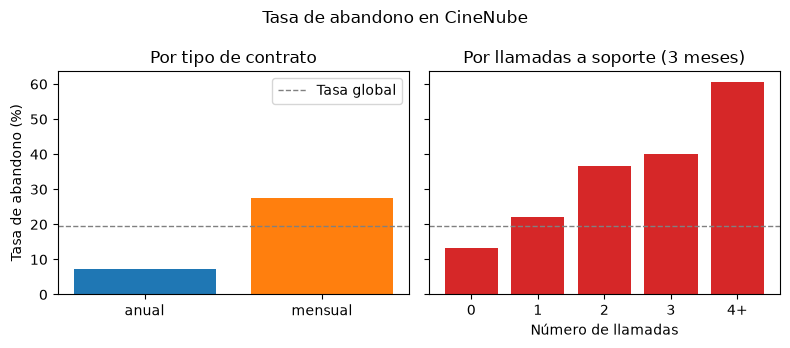

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5), sharey=True)

por_contrato = tasa_por(clientes["tipo_contrato"])["tasa_pct"]
ax1.bar(por_contrato.index, por_contrato.values, color=["tab:blue", "tab:orange"])
ax1.set_title("Por tipo de contrato")
ax1.set_ylabel("Tasa de abandono (%)")

por_llamadas = tasa_por(llamadas_grupo)["tasa_pct"]
ax2.bar(por_llamadas.index, por_llamadas.values, color="tab:red")
ax2.set_title("Por llamadas a soporte (3 meses)")
ax2.set_xlabel("Número de llamadas")

for ax in (ax1, ax2):
    ax.axhline(tasa_global, color="gray", linestyle="--", linewidth=1, label="Tasa global")
ax1.legend()
fig.suptitle("Tasa de abandono en CineNube")
fig.tight_layout()
plt.show()

**Hallazgos**

1. **El contrato mensual es el gran factor de riesgo.** Abandona el 27.5 % de los clientes mensuales frente al 7.4 % de los anuales, casi cuatro veces más. El pago manual también destaca: 28.2 % frente a 16.6 % del domiciliado y 18.2 % de la tarjeta.
2. **Las llamadas a soporte anticipan el abandono.** La tasa sube con cada llamada: 13.2 % sin llamadas, 22.0 % con una, 36.5 % con dos y 60.6 % con cuatro o más. Este último grupo solo tiene 33 clientes, así que su tasa es menos precisa.
3. **Quien se va usa menos el servicio y lleva menos tiempo.** Los que abandonan ven 4.21 horas por semana frente a 6.42, llevan 20.2 meses frente a 29.6 y pagan algo más (12.47 frente a 11.42 dólares).

Son comparaciones de una variable a la vez. Las variables están relacionadas entre sí (por ejemplo, los clientes mensuales suelen llevar menos tiempo), así que estas tasas no aíslan el efecto de cada una. Para eso sirve el modelo de la Tarea 6.

### Tarea 5. Preparación de los datos

In [7]:
X = pd.get_dummies(clientes.drop(columns=["cliente_id", "abandono"]),
                   columns=["tipo_contrato", "metodo_pago"], drop_first=True, dtype=int)
y = clientes["abandono"]

print("Columnas de X:", X.columns.tolist())
X.head()

Columnas de X: ['antiguedad_meses', 'cargo_mensual', 'horas_uso_semana', 'llamadas_soporte', 'tipo_contrato_mensual', 'metodo_pago_manual', 'metodo_pago_tarjeta']


,antiguedad_meses,cargo_mensual,horas_uso_semana,llamadas_soporte,tipo_contrato_mensual,metodo_pago_manual,metodo_pago_tarjeta
0,41,10.99,3.3,0,0,0,0
1,22,10.99,7.2,1,1,1,0
2,20,6.99,NaN,0,0,0,1
3,25,15.99,8.2,0,0,0,1
4,29,6.99,1.8,2,1,0,0


`drop_first=True` elimina la primera categoría en orden alfabético, que queda como **referencia**: `anual` en el tipo de contrato y `domiciliado` en el método de pago. Así, `tipo_contrato_mensual = 1` significa "mensual en lugar de anual", y los coeficientes de `metodo_pago_manual` y `metodo_pago_tarjeta` se leen frente al pago domiciliado. Quitar una categoría evita que las dummies de una variable sumen siempre 1, lo que las haría redundantes con el intercepto.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

print("Entrenamiento:", X_train.shape, f" tasa de abandono {y_train.mean() * 100:.1f} %")
print("Prueba:       ", X_test.shape, f" tasa de abandono {y_test.mean() * 100:.1f} %")
print("Faltantes en horas_uso_semana (entrenamiento / prueba):",
      X_train["horas_uso_semana"].isna().sum(), "/", X_test["horas_uso_semana"].isna().sum())

Entrenamiento: (3000, 7)  tasa de abandono 19.6 %
Prueba:        (1000, 7)  tasa de abandono 19.6 %
Faltantes en horas_uso_semana (entrenamiento / prueba): 97 / 28


**Estratificar** garantiza que entrenamiento y prueba tengan la misma proporción de abandonos (19.6 % en los dos). Sin estratificar, el azar podría dejar en la prueba más o menos abandonos de lo normal, y las métricas no representarían a la población. Esto importa más cuanto más rara es la clase positiva.

**Imputar después de dividir.** Si se calcula la mediana de `horas_uso_semana` con los 4000 clientes, la prueba aporta información al entrenamiento: es una **fuga de datos**, pequeña aquí, pero que hace que la evaluación sea optimista. Además, en el despliegue la cartera llegará después y no podrá influir en el modelo. Al poner `SimpleImputer` dentro del `Pipeline`, la mediana se aprende solo con los 3000 clientes de entrenamiento y se aplica tal cual a los 28 faltantes de la prueba y a los de la cartera. Lo mismo vale para el escalado.

### Tarea 6. Modelado y evaluación

El `Pipeline` encadena los tres pasos. Al llamar a `fit`, la mediana para imputar y la media y la desviación para escalar se calculan **solo con el entrenamiento**; al predecir sobre la prueba, se aplican esos mismos valores.

In [9]:
modelo = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
    ("logistica", LogisticRegression(max_iter=1000)),
])
modelo.fit(X_train, y_train)

proba_test = modelo.predict_proba(X_test)[:, 1]   # probabilidad de abandono
pred_test = (proba_test >= 0.5).astype(int)       # umbral por defecto

matriz = pd.DataFrame(confusion_matrix(y_test, pred_test),
                      index=["Real: se queda", "Real: abandona"],
                      columns=["Pred.: se queda", "Pred.: abandona"])
print(matriz, "\n")
print(f"Recall (clase 1):    {recall_score(y_test, pred_test):.3f}")
print(f"Precisión (clase 1): {precision_score(y_test, pred_test):.3f}")
print(f"ROC AUC:             {roc_auc_score(y_test, proba_test):.3f}")

                Pred.: se queda  Pred.: abandona
Real: se queda              773               31
Real: abandona              121               75 

Recall (clase 1):    0.383
Precisión (clase 1): 0.708
ROC AUC:             0.839


In [10]:
coeficientes = pd.Series(modelo.named_steps["logistica"].coef_[0], index=X.columns).sort_values()
coeficientes.round(3)

horas_uso_semana        -0.757
antiguedad_meses        -0.678
metodo_pago_tarjeta      0.052
metodo_pago_manual       0.308
cargo_mensual            0.369
llamadas_soporte         0.423
tipo_contrato_mensual    0.711
dtype: float64

**Evaluación técnica**

- **ROC AUC = 0.839.** Si se toma al azar un cliente que abandona y otro que se queda, el modelo asigna más riesgo al primero en el 84 % de los casos. Ordena bien a los clientes.
- **Con el umbral 0.5**, el modelo marca a 106 clientes, de los que 75 abandonan de verdad: **precisión 0.708**. Pero de los 196 que abandonan detecta solo a esos 75: **recall 0.383**. Deja escapar a 121, casi dos de cada tres.

**Coeficientes.** Están en la escala estandarizada, así que miden el cambio en el logaritmo de las odds de abandono por cada desviación estándar de la variable. En las dummies, la desviación estándar corresponde a la variable 0/1, de modo que el coeficiente compara con la categoría de referencia en esa escala.

- **Aumentan el riesgo:** el contrato mensual (0.711), las llamadas a soporte (0.423), el cargo mensual (0.369) y el pago manual (0.308).
- **Lo reducen:** las horas de uso (−0.757), el efecto más fuerte, y la antigüedad (−0.678).
- **Pago con tarjeta:** su coeficiente (0.052) es casi cero, así que apenas se diferencia del domiciliado. Coincide con la exploración (18.2 % frente a 16.6 %).

Son asociaciones, no causas: llamar a soporte no hace que un cliente se vaya, sino que delata un problema sin resolver.

**¿Basta el recall con el umbral 0.5?** No para el objetivo de retención, que es llegar a la mayor parte de los que se van. Pero 0.5 no tiene nada de especial: es un umbral por defecto. Bajarlo aumenta el recall a costa de la precisión. En CineNube el umbral lo fija el **presupuesto** de llamadas, y para eso lo que importa es que el modelo ordene bien (el AUC). Es la evaluación de negocio de la Tarea 7.

### Tarea 7. Despliegue: a quién llamar este mes

**Evaluación con el presupuesto.** El umbral que deja arriba al 10 % de mayor riesgo es el percentil 90 de las probabilidades.

In [11]:
umbral_10 = np.quantile(proba_test, 0.90)
llamar = proba_test >= umbral_10

captura = y_test[llamar].sum() / y_test.sum()
precision_top = y_test[llamar].mean()

print(f"Umbral (percentil 90): {umbral_10:.3f}")
print(f"Clientes llamados: {llamar.sum()} de {len(y_test)}")
print(f"Abandonos capturados: {y_test[llamar].sum()} de {y_test.sum()}  ->  captura {captura * 100:.1f} %")
print(f"Precisión del grupo llamado: {precision_top * 100:.1f} %")
print(f"Al azar: captura esperada 10.0 %, precisión esperada {y_test.mean() * 100:.1f} %")
print(f"El modelo concentra {captura / 0.10:.1f} veces más abandonos que llamar al azar")

Umbral (percentil 90): 0.511
Clientes llamados: 100 de 1000
Abandonos capturados: 70 de 196  ->  captura 35.7 %
Precisión del grupo llamado: 70.0 %
Al azar: captura esperada 10.0 %, precisión esperada 19.6 %
El modelo concentra 3.6 veces más abandonos que llamar al azar


La **curva de captura** (o de ganancia acumulada) muestra lo mismo para cualquier presupuesto: ordenamos a los clientes de mayor a menor riesgo y, para cada porcentaje contactado, calculamos qué porcentaje de los abandonos ya está incluido.

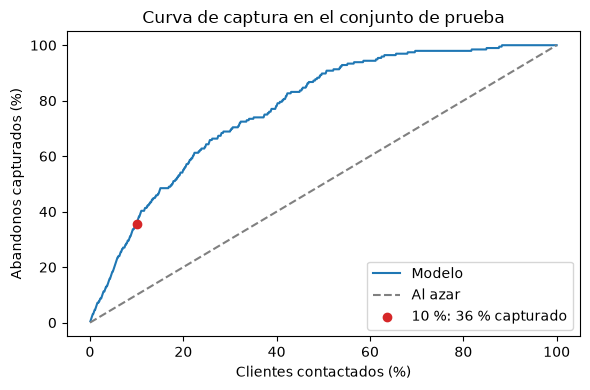

Llamando al 10 %: captura 35.7 %
Llamando al 20 %: captura 55.1 %
Llamando al 30 %: captura 68.9 %


In [12]:
orden = np.argsort(-proba_test)
captura_acum = np.cumsum(y_test.to_numpy()[orden]) / y_test.sum() * 100
contactados = np.arange(1, len(orden) + 1) / len(orden) * 100

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(contactados, captura_acum, label="Modelo")
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", label="Al azar")
ax.scatter([10], [captura * 100], color="tab:red", zorder=3, label=f"10 %: {captura * 100:.0f} % capturado")
ax.set_xlabel("Clientes contactados (%)")
ax.set_ylabel("Abandonos capturados (%)")
ax.set_title("Curva de captura en el conjunto de prueba")
ax.legend()
fig.tight_layout()
plt.show()

for pct in (10, 20, 30):
    print(f"Llamando al {pct} %: captura {captura_acum[int(len(orden) * pct / 100) - 1]:.1f} %")

**Puntuar la cartera.** La cartera pasa por las mismas transformaciones que el entrenamiento: las mismas dummies, en el mismo orden de columnas (`reindex` lo garantiza aunque falte alguna categoría), y después por el `Pipeline` ya entrenado, que imputa y escala con los valores aprendidos.

In [13]:
X_cartera = (pd.get_dummies(cartera.drop(columns="cliente_id"),
                            columns=["tipo_contrato", "metodo_pago"], drop_first=True, dtype=int)
             .reindex(columns=X.columns, fill_value=0))

cartera_puntuada = cartera.assign(prob_abandono=modelo.predict_proba(X_cartera)[:, 1])

n_llamar = int(len(cartera) * 0.10)
lista = cartera_puntuada.nlargest(n_llamar, "prob_abandono")

print(f"Clientes a llamar: {len(lista)} de {len(cartera)}")
print(f"Umbral de probabilidad en la cartera: {lista['prob_abandono'].min():.3f}")
print(f"Riesgo medio de la lista: {lista['prob_abandono'].mean():.3f}  "
      f"(cartera completa: {cartera_puntuada['prob_abandono'].mean():.3f})")
lista.head(10).round({"prob_abandono": 3})

Clientes a llamar: 100 de 1000


Umbral de probabilidad en la cartera: 0.467
Riesgo medio de la lista: 0.623  (cartera completa: 0.196)


,cliente_id,tipo_contrato,metodo_pago,antiguedad_meses,cargo_mensual,horas_uso_semana,llamadas_soporte,prob_abandono
864,10865,mensual,manual,30,20.99,1.0,4,0.939
533,10534,mensual,manual,8,15.99,3.0,3,0.909
40,10041,mensual,tarjeta,4,18.49,2.0,3,0.906
588,10589,mensual,manual,2,10.99,4.4,3,0.854
287,10288,mensual,tarjeta,8,18.49,1.3,2,0.850
316,10317,mensual,tarjeta,1,10.99,1.8,3,0.842
802,10803,mensual,manual,6,10.99,1.7,2,0.839
750,10751,mensual,manual,22,13.49,1.9,3,0.839
32,10033,mensual,tarjeta,13,10.99,1.9,4,0.833
258,10259,mensual,manual,27,13.49,1.8,3,0.809


**Evaluación frente al objetivo de negocio.** Llamar al 10 % de mayor riesgo del conjunto de prueba (100 clientes) alcanza a 70 de los 196 que abandonan: una **captura del 35.7 %** con una **precisión del 70 %**. Al azar, las mismas 100 llamadas alcanzarían a un 10 % de los que se van, con una precisión del 19.6 %. El modelo concentra **3.6 veces** más abandonos, por encima del criterio de éxito fijado en la Tarea 1 (el triple). Por coincidencia, el umbral del percentil 90 (0.511) queda muy cerca de 0.5, así que este grupo es casi el mismo que el de la Tarea 6; con otro presupuesto el umbral sería distinto.

La curva de captura muestra el rendimiento decreciente: con el 20 % de los clientes se captura el 55.1 % de los abandonos y con el 30 %, el 68.9 %. Si la dirección duplicara el presupuesto, cada llamada extra rendiría menos que las primeras.

**Lista de la cartera.** Con el mismo criterio salen **100 clientes** de los 1000 activos, con un umbral de 0.467 y un riesgo medio de 0.623, frente a 0.196 de toda la cartera. Los diez primeros tienen el perfil que mostró la exploración: todos con contrato mensual, con pago manual o con tarjeta, entre 1 y 4.4 horas de uso por semana y de 2 a 4 llamadas a soporte.

**Qué decirle a la dirección**

- Con el mismo presupuesto, las llamadas llegan a unas tres veces y media más clientes que de verdad están por irse.
- **Capturar no es retener.** El modelo dice a quién llamar, no si la oferta funciona. Para medir el beneficio real conviene dejar sin llamar a una parte elegida al azar de la lista de alto riesgo (**grupo de control**) y comparar sus tasas de abandono.

**Qué monitorear**

- La tasa de abandono real de los clientes puntuados frente a la predicha, y la captura mes a mes.
- Cambios en la distribución de las variables: una subida de precios, una nueva aplicación que cambie el registro de uso o más faltantes en `horas_uso_semana`.
- Las ofertas aplicadas: los clientes llamados cambian de comportamiento, y hay que registrarlo para no entrenar el siguiente modelo con datos contaminados.

El modelo debe reentrenarse con datos recientes cuando su desempeño baje.

## Conclusiones

- Uno de cada cinco suscriptores de CineNube cancela en tres meses (19.6 %). El perfil de riesgo combina contrato mensual, poco uso, poca antigüedad, llamadas repetidas a soporte y pago manual.
- La regresión logística ordena bien a los clientes (ROC AUC de 0.84), pero con el umbral por defecto solo detecta al 38 % de los que se van: el umbral debe fijarlo el negocio, no el algoritmo.
- Con el presupuesto del 10 %, el modelo captura el 36 % de los abandonos con una precisión del 70 %, 3.6 veces más que llamar al azar. Eso cumple el criterio de éxito fijado en la comprensión del negocio.
- Los hallazgos sugieren palancas más allá de las llamadas: promover el contrato anual y el pago domiciliado, resolver a la primera los problemas de soporte y reactivar a quienes dejan de usar el servicio. Su efecto debe comprobarse con experimentos, porque el modelo muestra asociaciones.
- El valor del proyecto apareció al conectar el modelo con el presupuesto de retención y con su uso mensual: son las fases de evaluación y despliegue de CRISP-DM, las que KDD no desarrolla.